### TEL351 – Seminario de Telemática I
# Clase 6: Community Detection and Graph Embeddings
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Detección de Comunidades

<div align="center">
<img src="img/comunidades.jpg" alt="" width="15%" align="right" />
</div>

Las redes son parte integral de muchos problemas del mundo real, por lo tanto, los algoritmos de detección comunitaria se han abierto camino en varios campos, que van desde el análisis de redes sociales hasta iniciativas de salud pública. Por ejemplo:

- Detección de grupos terroristas mediante el seguimiento de sus actividades e interacciones.
- Identificación de grupos susceptibles a enfermedades epidémicas.
- Predicción de la evolución en una comunidad, analizando cambios en la estructura de la red.

## Técnicas de detección comunitaria 

- Métodos aglomerativos: Comienzan con una red que contiene solo nodos del grafo original y las aristas se van agregando una por una, priorizando las con más peso.

- Métodos divisivos: Eliminan aristas del grafo original de forma iterativa. Las aristas con menos peso se eliminan primero y en cada paso, se vuelve a calcular el peso de las aristas restantes. Después de una cierta cantidad de divisiones, se obtienen grupos de nodos densamente conectados, también conocidos como comunidades.

<div align="center">
<img src="img/divisivo.png" alt="" width="15%" align="center" />
</div>

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

In [2]:
plt.rcParams['image.cmap'] = 'Set3'

In [3]:
df = pd.read_csv("marvel.csv", header=None, names=['Source','Target'])

In [4]:
df

,Source,Target
0,"FROST, CARMILLA",AA2 35
1,KILLRAVEN/JONATHAN R,AA2 35
2,M'SHULLA,AA2 35
3,24-HOUR MAN/EMMANUEL,AA2 35
4,OLD SKULL,AA2 35
...,...,...
96650,M'SHULLA,AA2 20
96651,OLD SKULL,AA2 20
96652,MASTER FOUR,AA2 20
96653,WARLORD,AA2 20


In [5]:
full_network = nx.from_pandas_edgelist(df, 
                            source='Source',
                            target='Target')

In [6]:
print(full_network)

Graph with 19291 nodes and 96519 edges


In [7]:
degrees = dict(nx.degree(full_network))

In [8]:
SG = full_network.subgraph([n for n in degrees if degrees[n]>10])

In [9]:
print(SG)

Graph with 4425 nodes and 40565 edges


In [10]:
G = SG.subgraph(max(nx.connected_components(SG), key=len))

In [11]:
print(G)

Graph with 4386 nodes and 40565 edges


In [12]:
d = {}
for n in G.nodes():
    if "[" in n:
        i = n.index("[")
        name = n[:i].strip()
    else:
        name = n
    if "/" in name:
        i = name.index("/")
        name = name[:i].strip()
        d[n] = name.replace(" ","\n").title().strip()
    else:
        d[n] = name.replace(" ","\n").title().strip()

In [13]:
inverted_dict = {value: key for key, value in d.items()}

In [14]:
def sizes(G, degrees, threshold=500, minsize=100):
    out = []
    for node in G.nodes():
        if degrees[node] <= threshold:
            size = minsize
        else:
            size = 100*degrees[node]**0.5
        out.append(size)
    return out

In [15]:
def plot_graph(G, pos, degrees, threshold=500, title="Marvel Network", node_color="white", minsize=100):
    plt.figure(figsize=(20,10))
    s = sizes(G, degrees, threshold, minsize)
    ns = nx.draw_networkx_nodes(G, pos, nodelist=G.nodes, node_size=s, node_color=node_color)
    ns.set_edgecolor('#707070')
    nx.draw_networkx_labels(G,pos,{n:d[n] for n in d if degrees[n]>threshold},font_size=10)
    nx.draw_networkx_edges(G,pos,G.edges,edge_color='#707070')
    plt.title(title,fontsize = 24)
    plt.axis('off')
    plt.show()

In [16]:
threshold = 200

# Identify high-degree nodes
high_degree_nodes = [node for node, degree in degrees.items() if degree > threshold]

# Create spring layout with repulsion-only for high-degree nodes
high_degree_graph = G.subgraph(high_degree_nodes)
high_degree_pos = nx.spring_layout(high_degree_graph, k=100)

# Calculate positions for the rest of the nodes
non_high_degree_nodes = set(G.nodes()) - set(high_degree_nodes)
non_high_degree_pos = nx.spring_layout(G.subgraph(non_high_degree_nodes), k=0.1)

# Merge positions of high-degree and non-high-degree nodes
pos = {**high_degree_pos, **non_high_degree_pos}

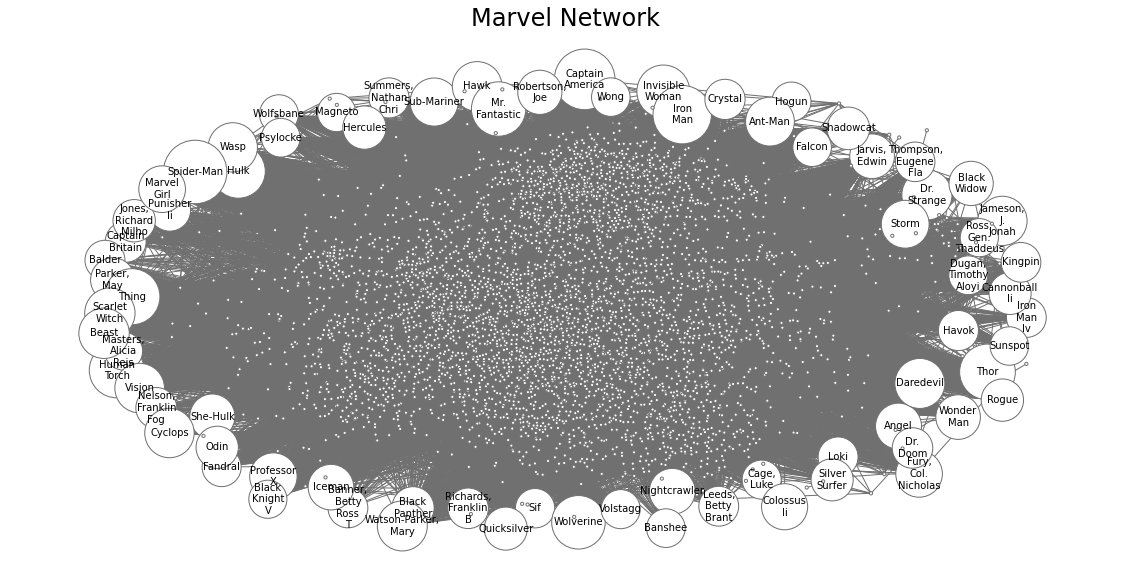

In [17]:
plot_graph(G, pos, degrees, threshold=200, minsize=10)

#### Modularidad

La modularidad es una medida de la estructura de las redes o grafos que mide la fuerza de la división de una red.

<div align="center">
<img src="img/modularidad.png" alt="" width="50%" align="center" />
</div>

### Louvain Community Detection

Primero se encuentran comunidades pequeñas optimizando la modularidad localmente para todos los nodos, luego cada comunidad pequeña se asocia a un nodo y se repite el proceso hasta alcanzar la convergencia.

<div align="center">
<img src="img/Louvain.png" alt="" width="55%" align="center" />
</div>

In [18]:
from networkx import community

In [19]:
louvain = community.louvain_communities(G, resolution=0.3, seed=0)
print("Comunidades detectadas con Louvain:",len(louvain))

Comunidades detectadas con Louvain: 6


In [20]:
louvain_communities = []
i = 0
for x in louvain:
    for node in x:
        louvain_communities.append(i)
    i += 1

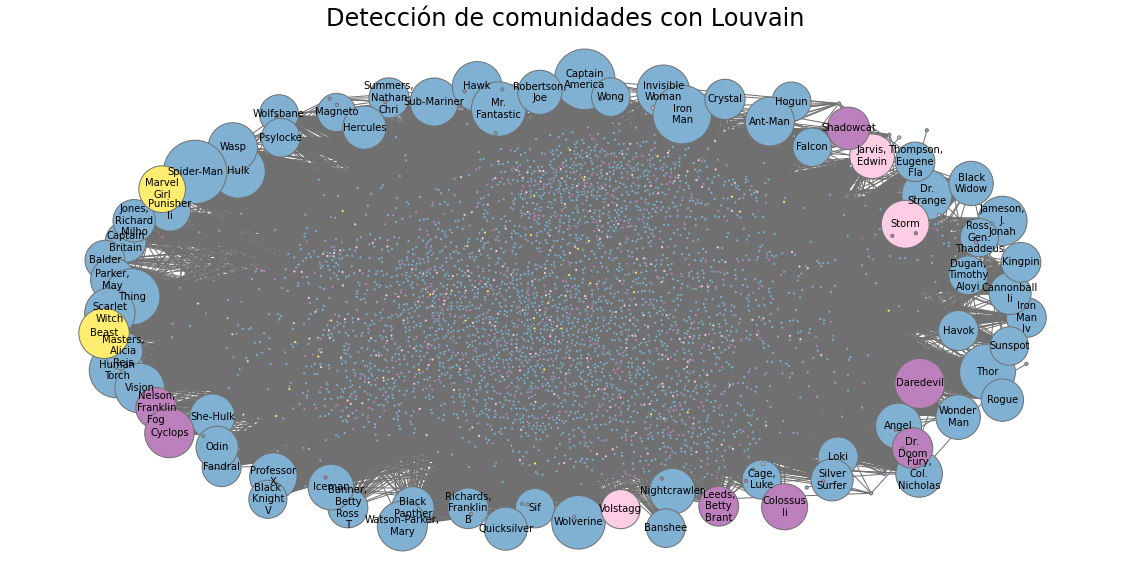

In [21]:
plot_graph(G, pos, degrees, threshold=200, title="Detección de comunidades con Louvain", node_color=louvain_communities, minsize=10)

### Fluid Communities

El algoritmo se basa en la idea simple de fluidos que interactúan en un entorno, expandiéndose y empujándose unos a otros. Su inicialización es aleatoria, por lo que las comunidades encontradas pueden variar en diferentes ejecuciones.

Parámetro `k`: El número de comunidades a encontrar.

In [22]:
from networkx.algorithms.community import asyn_fluidc

In [23]:
fluid = asyn_fluidc(G, k=5, seed=0)

In [24]:
fluid_communities = []
i = 0
for x in fluid:
    for node in x:
        fluid_communities.append(i)
    i += 1

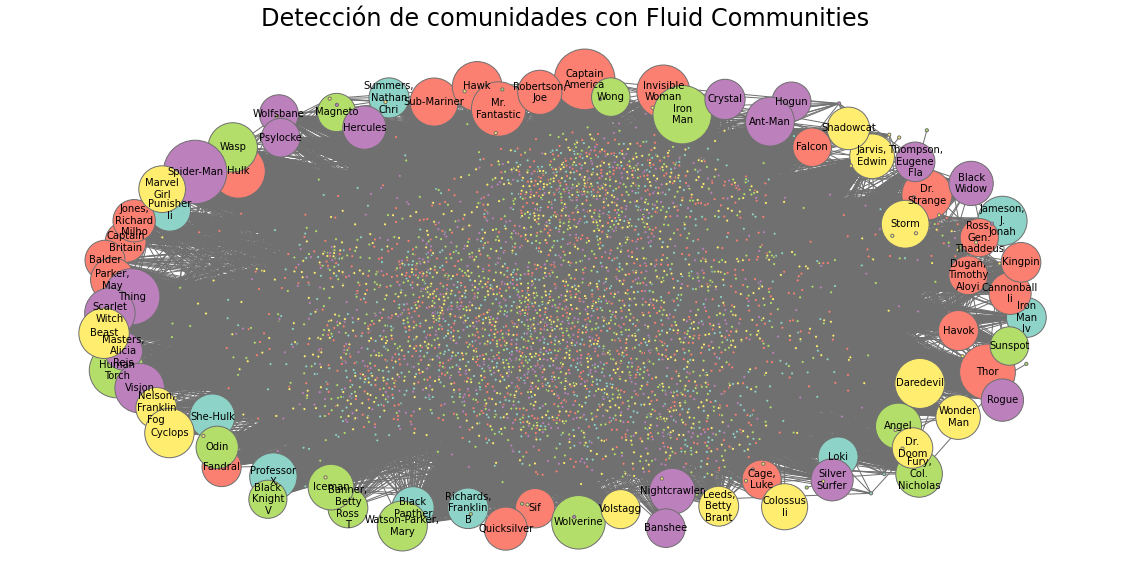

In [25]:
plot_graph(G, pos, degrees, threshold=200, title="Detección de comunidades con Fluid Communities", node_color=fluid_communities, minsize=10)

# Graph Embeddings
<div align="center">
<img src="img/graph_embeddings.png" alt="" width="100%" align="center" />
</div>

# Node embeddings

- Son una forma de representar nodos como vectores.
- Capturan la topología de la red.
- Se basan en la noción de similitud.
- Pueden ser utilizados para tareas de predicción en *Machine Learning*.

<div align="center">
<img src="img/node_embeddings.png" alt="" width="100%" align="center" />
</div>

# Random walk based
<div align="center">
<img src="img/random_walk_based.jpg" alt="" width="100%" align="center" />
</div>

## DeepWalk

Método para aprender representaciones de nodos en un grafo. La idea principal detrás de DeepWalk es generar Random Walks en el grafo y utilizar estas caminatas aleatorias para aprender representaciones de nodos mediante el algoritmo Word2Vec.

<div align="center">
<img src="img/walks.png" alt="" width="50%" align="center" />
</div>

### Random walk

Genera un conjunto de recorridos aleatorios a partir de cada nodo del gráfico. Cada recorrido aleatorio es simplemente una secuencia de nodos que comienza en un nodo particular y se mueve a uno de sus vecinos en cada paso. Estos recorridos aleatorios capturan la estructura local del gráfico y proporcionan una forma de aprender representaciones de nodos que capturan sus relaciones con los nodos cercanos.

<div align="center">
<img src="img/drunk.png" alt="" width="30%" align="left" />
<img src="img/random_walk.png" alt="" width="30%" align="center" />
</div>

### Word2Vec

Word2Vec es un algoritmo popular para aprender representaciones de palabras en el procesamiento del lenguaje natural, pero también se puede aplicar para aprender representaciones de nodos en un grafo. 

Dependiendo del enfoque, hay dos variantes principales:

1. **Skip-gram:** Predice las palabras de contexto que rodean una palabra objetivo.

<div align="center">
<img src="img/skip-gram.png" alt="" width="20%" align="center" />
</div>

2. **CBOW (Continuous Bag of Words):** Predice una palabra dada su ventana de palabras de contexto.

<div align="center">
<img src="img/CBOW.png" alt="" width="30%" align="center" />
</div>

En el caso de DeepWalk, los recorridos aleatorios generados a partir del grafo sirven como "frases" y los nodos sirven como "palabras". Luego, el algoritmo Word2Vec se usa para aprender una red neuronal que predice la probabilidad de que un nodo aparezca en una caminata aleatoria dados sus vecinos en el grafo. Las representaciones aprendidas de los nodos se pueden usar para una variedad de tareas posteriores, como la clasificación de nodos o la predicción de enlaces.

## Node2Vec

- Node2Vec es un algoritmo de Node Embeddings que calcula una representación vectorial de un nodo en función de Random Walks en el grafo. El modelo aprende representaciones en un espacio de baja dimensionalidad para los nodos optimizando una función objetivo que preserva el vecindario usando Random Walks.

- El vecindario se muestrea a través de caminatas aleatorias. Usando una cantidad de muestras de vecindario aleatorias, el algoritmo entrena una red neuronal de una sola capa oculta. La red neuronal está entrenada para predecir la probabilidad de que ocurra un nodo en una caminata en función de la ocurrencia de otro nodo.

<div align="center">
<img src="img/node2vec.png" alt="" width="100%" align="center" />
</div>

## Diferencia con DeepWalk

Node2Vec es similar a DeepWalk, pero la principal diferencia es que, cuando usa random walks, existe una cierta probabilidad de volver atrás al nodo anterior:

Después de la transición al nodo $v$ desde $t$, el hiperparámetro de retorno ($p$) y el hiperparámetro de entrada y salida ($q$), controlan la probabilidad de que una caminata se devuelva a visitar el nodo $t$, permanezca cerca de los nodos anteriores ($x_1$) o se aleje ($x_2$, $x_3$).

<div align="center">
<img src="img/walk.png" alt="" width="20%" align="center" />
</div>

In [26]:
# !pip install Node2Vec

In [27]:
from node2vec import Node2Vec

In [28]:
node2vec = Node2Vec(G, dimensions=10, seed=0)
model = node2vec.fit(window=10)

Computing transition probabilities:   0%|          | 0/4386 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 10/10 [01:03<00:00,  6.34s/it]


In [29]:
model.wv.most_similar(inverted_dict['Hulk'])

[('H2 207', 0.977489173412323),
 ('H@ 18/2', 0.9573630690574646),
 ('H2 383', 0.9560333490371704),
 ('H2 209', 0.953452467918396),
 ('H2 206', 0.9534432888031006),
 ('DEF 7', 0.9511683583259583),
 ('DEF 25', 0.9498149156570435),
 ('DEF 24', 0.9482292532920837),
 ('TALBOT, GLENN', 0.939481258392334),
 ('DEF 99', 0.9348167777061462)]

In [30]:
model.wv.most_similar(inverted_dict['Spider-Man'])

[('ASM@ 21', 0.9924889206886292),
 ('WATSON-PARKER, MARY ', 0.9908878803253174),
 ('ASM 156', 0.9898081421852112),
 ('ASM:FO 1', 0.9898058772087097),
 ('PPTSS@ 9/3', 0.9890782833099365),
 ('ASM 112', 0.9890024065971375),
 ('ASM 167', 0.9882174730300903),
 ('PPSM2 19', 0.9867141246795654),
 ('PPTSS 174', 0.9851182699203491),
 ('OSBORN, LIZ ALLAN', 0.9844512343406677)]

In [31]:
model.wv.most_similar(inverted_dict['Rogue'])

[('PSYLOCKE/ELISABETH B', 0.9903526902198792),
 ('X 103', 0.9872671961784363),
 ('UX 143', 0.9814004302024841),
 ('X 84', 0.9811092019081116),
 ('UX 362', 0.9807276725769043),
 ('STORM/ORORO MUNROE S', 0.9780555963516235),
 ('X@ 1', 0.9774870872497559),
 ('WOLVERINE/LOGAN ', 0.9763356447219849),
 ('W2 145', 0.9758681058883667),
 ('UX 389', 0.9750813841819763)]

In [32]:
emb_df = (pd.DataFrame([model.wv.get_vector(str(n)) for n in G.nodes()], index = G.nodes))
emb_df.head()

,0,1,2,3,4,5,6,7,8,9
NM 20,0.341570,0.003985,0.468196,0.971023,0.398760,0.395925,0.168957,0.279537,-0.988154,-1.599743
KRAVEN THE HUNTER/SE,-0.418345,-0.781087,-0.679983,-0.290298,-0.086258,-0.394136,1.342445,-0.291808,-0.637098,-0.211411
MAXSEC 2,-0.331335,-0.384791,0.427655,-0.330860,-0.122301,0.495339,0.294252,0.796340,-0.551671,-0.049846
CA 409,0.595525,-0.301404,-0.266326,-1.330236,0.165254,0.528773,-0.361096,-0.168514,-1.569560,0.541785
CA3 13,0.084834,-0.744446,0.020902,-1.022623,0.683221,0.578717,0.255206,0.696006,-0.457297,0.088976


In [33]:
from sklearn.manifold import TSNE

In [34]:
t_sne = TSNE(n_components=2, perplexity=5, init="pca", n_iter=250, random_state=0, learning_rate='auto').fit_transform(emb_df)

In [35]:
def plot_embedding(embedding, degrees, threshold=200, node_colors='gray', title='Node Embedding de la Marvel Network'):
    plt.figure(figsize=(20,10))
    plt.scatter(embedding[:,0], embedding[:,1], s = 80, alpha = 0.5, c=node_colors, zorder=1)
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.title(title)
    for i, word in enumerate(list(G.nodes)):
        if degrees[word] > threshold:
            plt.annotate(d[word].replace("\n"," "), xy=(embedding[i, 0], embedding[i, 1]), 
                         size=(degrees[word]/50 if degrees[word]/50 >= 10 else 10), zorder=3)  
        
    plt.show()

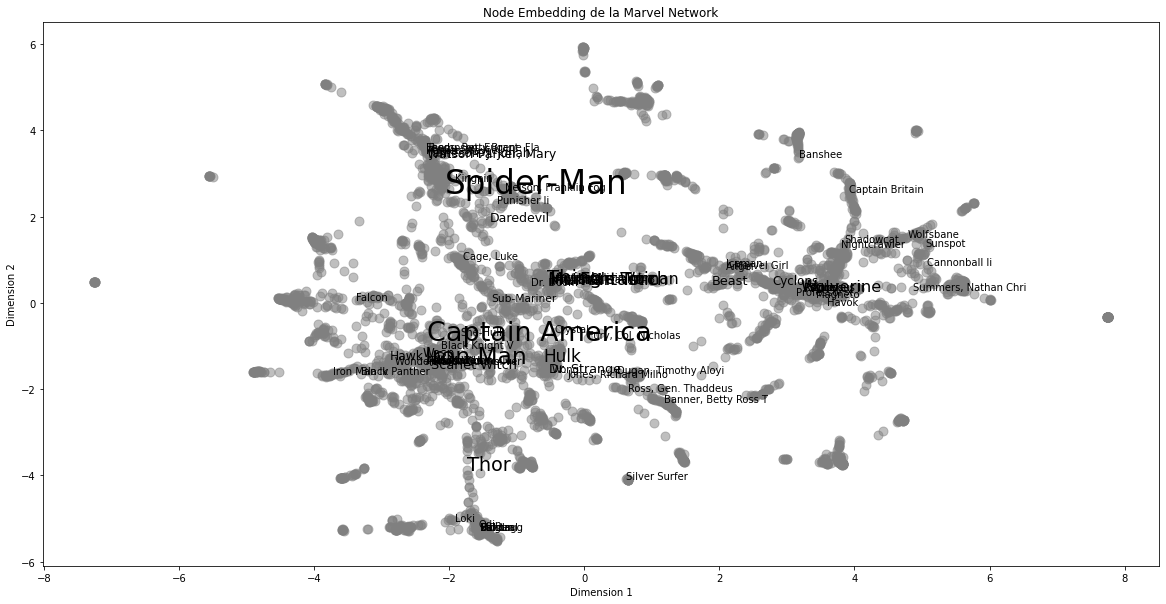

In [36]:
plot_embedding(t_sne, degrees, threshold=200)

In [37]:
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

In [38]:
clustering = KMeans(n_clusters=5, random_state=0).fit(t_sne)

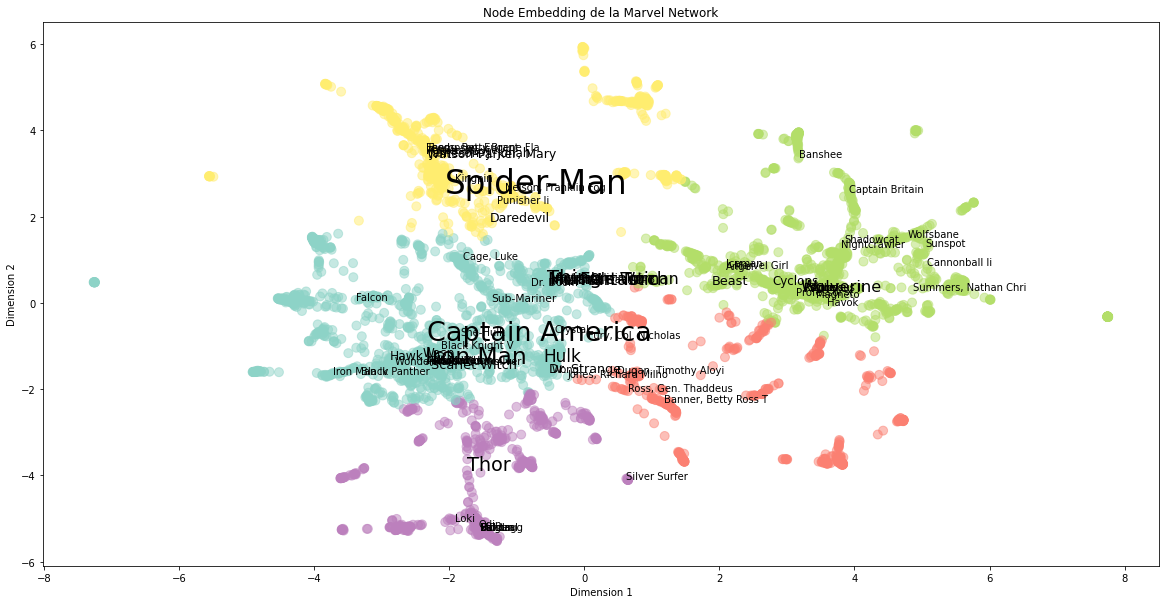

In [39]:
plot_embedding(t_sne, degrees, threshold=200, node_colors=clustering.labels_)

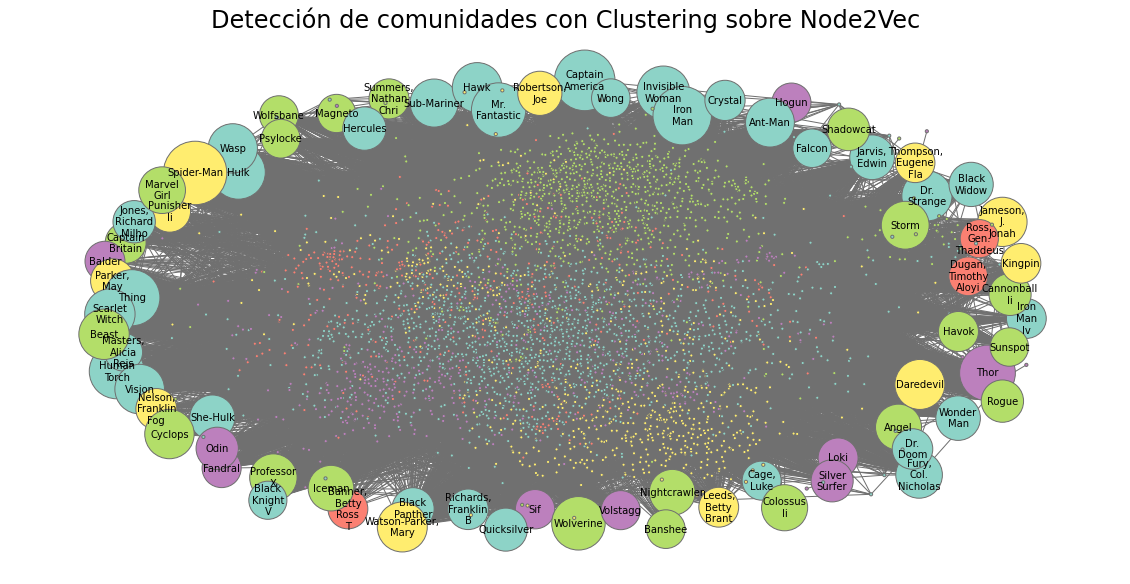

In [40]:
plot_graph(G, pos, degrees, threshold=200, title="Detección de comunidades con Clustering sobre Node2Vec", node_color=clustering.labels_, minsize=10)